In [1]:
%pip install pandas numpy matplotlib scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ["MPLCONFIGDIR"] = ".mplconfig"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances
)

from scipy.optimize import linear_sum_assignment

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

RANDOM_STATE = 42

Matplotlib is building the font cache; this may take a moment.


In [6]:
from pathlib import Path

FILE_PATH = Path("ml_training_features.csv")
if not FILE_PATH.exists():
    FILE_PATH = Path("..") / "ml_training_features.csv"

df = pd.read_csv(FILE_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (2869, 16)

Column names:
['customer_id', 'log_avg_monthly_balance', 'log_balance_volatility_ratio', 'balance_growth_rate', 'log_txn_frequency_per_month', 'active_months_ratio', 'log_days_since_last_txn', 'log_avg_txn_amount', 'txn_amount_cv', 'high_value_txn_ratio', 'net_cash_flow_ratio', 'debit_txn_share', 'log_account_tenure_months', 'num_active_products', 'log_overdraft_month_count', 'digital_channel_ratio']


,customer_id,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio
0,4568,14.108626,0.429545,0.124513,2.377486,1.000000,1.609438,11.853256,1.339462,0.380682,-0.013393,0.602273,4.615121,5.0,0.693147,0.585227
1,4575,14.180201,0.260070,0.594323,2.623057,1.000000,1.098612,11.563021,1.073933,0.347826,-0.117187,0.652174,4.276666,6.0,0.000000,0.495652
2,4576,12.069713,0.300179,0.866448,1.252763,0.833333,2.302585,6.836689,0.433865,0.000000,0.590075,0.266667,1.791759,2.0,0.000000,0.800000
3,4577,11.439775,0.203767,0.818096,1.280934,0.933333,2.833213,6.681168,0.581827,0.000000,0.479429,0.435897,2.772589,1.0,0.000000,0.923077
4,4578,12.159989,0.271701,0.875403,1.232144,0.857143,1.609438,7.058707,0.750023,0.000000,0.598006,0.352941,1.945910,1.0,0.000000,0.941176


In [14]:
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Cleaned column names:")
for column in df.columns:
    print(column)

Cleaned column names:
customer_id
log_avg_monthly_balance
log_balance_volatility_ratio
balance_growth_rate
log_txn_frequency_per_month
active_months_ratio
log_days_since_last_txn
log_avg_txn_amount
txn_amount_cv
high_value_txn_ratio
net_cash_flow_ratio
debit_txn_share
log_account_tenure_months
num_active_products
log_overdraft_month_count
digital_channel_ratio


In [15]:
feature_columns = [
    "avg_monthly_balance",
    "total_lifetime_deposits",
    "total_lifetime_withdrawals",
    "deposit_withdrawal_ratio",
    "avg_transaction_size",
    "transaction_frequency_per_month",
    "days_since_last_transaction",
    "account_tenure_months",
    "num_overdraft_events",
    "max_balance",
    "min_balance",
    "std_dev_transaction_amount",
    "num_active_products",
    "avg_gap_between_transactions_days",
    "high_value_transaction_ratio"
]

missing_columns = [
    column
    for column in feature_columns
    if column not in df.columns
]

if missing_columns:
    print("These columns are still missing:")
    print(missing_columns)
else:
    print("All 15 clustering features were found.")

These columns are still missing:
['avg_monthly_balance', 'total_lifetime_deposits', 'total_lifetime_withdrawals', 'deposit_withdrawal_ratio', 'avg_transaction_size', 'transaction_frequency_per_month', 'days_since_last_transaction', 'account_tenure_months', 'num_overdraft_events', 'max_balance', 'min_balance', 'std_dev_transaction_amount', 'avg_gap_between_transactions_days', 'high_value_transaction_ratio']


In [18]:
# Detect identifier columns
id_columns = [
    column for column in df.columns
    if column.lower() in [
        "id",
        "customer_id",
        "customerid",
        "account_id",
        "accountid"
    ]
]

# If the dataset has 16 columns and no ID was detected,
# treat the first column as the customer identifier
if not id_columns and df.shape[1] == 16:
    id_columns = [df.columns[0]]

print("Identifier column excluded:", id_columns)

# Keep every column except the identifier
X = df.drop(columns=id_columns, errors="ignore").copy()

# Convert all feature values to numbers
X = X.apply(pd.to_numeric, errors="coerce")

# Remove columns that contain no numerical data
X = X.dropna(axis=1, how="all")

# Replace infinity with missing values
X.replace([np.inf, -np.inf], np.nan, inplace=True)

feature_columns = X.columns.tolist()

print("Number of features selected:", len(feature_columns))
print("Selected features:")

for number, column in enumerate(feature_columns, start=1):
    print(number, column)

print("\nFeature dataset shape:", X.shape)
display(X.head())

Identifier column excluded: ['customer_id']
Number of features selected: 15
Selected features:
1 log_avg_monthly_balance
2 log_balance_volatility_ratio
3 balance_growth_rate
4 log_txn_frequency_per_month
5 active_months_ratio
6 log_days_since_last_txn
7 log_avg_txn_amount
8 txn_amount_cv
9 high_value_txn_ratio
10 net_cash_flow_ratio
11 debit_txn_share
12 log_account_tenure_months
13 num_active_products
14 log_overdraft_month_count
15 digital_channel_ratio

Feature dataset shape: (2869, 15)


,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio
0,14.108626,0.429545,0.124513,2.377486,1.000000,1.609438,11.853256,1.339462,0.380682,-0.013393,0.602273,4.615121,5.0,0.693147,0.585227
1,14.180201,0.260070,0.594323,2.623057,1.000000,1.098612,11.563021,1.073933,0.347826,-0.117187,0.652174,4.276666,6.0,0.000000,0.495652
2,12.069713,0.300179,0.866448,1.252763,0.833333,2.302585,6.836689,0.433865,0.000000,0.590075,0.266667,1.791759,2.0,0.000000,0.800000
3,11.439775,0.203767,0.818096,1.280934,0.933333,2.833213,6.681168,0.581827,0.000000,0.479429,0.435897,2.772589,1.0,0.000000,0.923077
4,12.159989,0.271701,0.875403,1.232144,0.857143,1.609438,7.058707,0.750023,0.000000,0.598006,0.352941,1.945910,1.0,0.000000,0.941176


In [19]:
missing_report = pd.DataFrame({
    "Missing Values": X.isnull().sum(),
    "Missing Percentage": (X.isnull().mean() * 100).round(2)
})

print("Missing values before cleaning:")
display(missing_report)

# Replace missing values with the median of each feature
X_clean = X.fillna(X.median())

print("\nTotal missing values after cleaning:")
print(X_clean.isnull().sum().sum())

print("\nCleaned dataset shape:")
print(X_clean.shape)

display(X_clean.head())

Missing values before cleaning:


,Missing Values,Missing Percentage
log_avg_monthly_balance,0,0.0
log_balance_volatility_ratio,0,0.0
balance_growth_rate,0,0.0
log_txn_frequency_per_month,0,0.0
active_months_ratio,0,0.0
log_days_since_last_txn,0,0.0
log_avg_txn_amount,0,0.0
txn_amount_cv,0,0.0
high_value_txn_ratio,0,0.0
net_cash_flow_ratio,0,0.0



Total missing values after cleaning:
0

Cleaned dataset shape:
(2869, 15)


,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio
0,14.108626,0.429545,0.124513,2.377486,1.000000,1.609438,11.853256,1.339462,0.380682,-0.013393,0.602273,4.615121,5.0,0.693147,0.585227
1,14.180201,0.260070,0.594323,2.623057,1.000000,1.098612,11.563021,1.073933,0.347826,-0.117187,0.652174,4.276666,6.0,0.000000,0.495652
2,12.069713,0.300179,0.866448,1.252763,0.833333,2.302585,6.836689,0.433865,0.000000,0.590075,0.266667,1.791759,2.0,0.000000,0.800000
3,11.439775,0.203767,0.818096,1.280934,0.933333,2.833213,6.681168,0.581827,0.000000,0.479429,0.435897,2.772589,1.0,0.000000,0.923077
4,12.159989,0.271701,0.875403,1.232144,0.857143,1.609438,7.058707,0.750023,0.000000,0.598006,0.352941,1.945910,1.0,0.000000,0.941176


In [20]:
display(X_clean.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
log_avg_monthly_balance,2869.0,12.32,2.03,-8.07,11.71,12.14,14.23,15.92
log_balance_volatility_ratio,2869.0,0.41,0.35,0.05,0.20,0.28,0.43,1.39
balance_growth_rate,2869.0,0.18,0.65,-1.00,-0.20,0.13,0.82,3.00
log_txn_frequency_per_month,2869.0,1.68,0.67,0.48,1.15,1.67,2.32,2.76
active_months_ratio,2869.0,0.86,0.19,0.28,0.83,0.94,1.00,1.00
log_days_since_last_txn,2869.0,2.19,1.53,0.69,1.10,1.79,2.48,6.04
log_avg_txn_amount,2869.0,8.56,1.91,6.17,6.90,8.11,11.20,12.03
txn_amount_cv,2869.0,0.81,0.29,0.30,0.59,0.77,0.94,2.18
high_value_txn_ratio,2869.0,0.09,0.15,0.00,0.00,0.00,0.21,0.46
net_cash_flow_ratio,2869.0,0.07,0.36,-1.00,-0.13,0.03,0.32,0.89


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_clean)

print("Scaled dataset shape:", X_scaled.shape)
print("Overall mean:", round(X_scaled.mean(), 4))
print("Overall standard deviation:", round(X_scaled.std(), 4))

Scaled dataset shape: (2869, 15)
Overall mean: 0.0
Overall standard deviation: 1.0


In [22]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20,
    max_iter=300
)

cluster_labels = kmeans.fit_predict(X_scaled)

df_clustered = df.copy()
df_clustered["cluster_id"] = cluster_labels

print("K-Means clustering completed.")
print("\nCluster labels:", sorted(df_clustered["cluster_id"].unique()))

display(df_clustered.head())

K-Means clustering completed.

Cluster labels: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4)]


,customer_id,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio,cluster_id
0,4568,14.108626,0.429545,0.124513,2.377486,1.000000,1.609438,11.853256,1.339462,0.380682,-0.013393,0.602273,4.615121,5.0,0.693147,0.585227,4
1,4575,14.180201,0.260070,0.594323,2.623057,1.000000,1.098612,11.563021,1.073933,0.347826,-0.117187,0.652174,4.276666,6.0,0.000000,0.495652,4
2,4576,12.069713,0.300179,0.866448,1.252763,0.833333,2.302585,6.836689,0.433865,0.000000,0.590075,0.266667,1.791759,2.0,0.000000,0.800000,1
3,4577,11.439775,0.203767,0.818096,1.280934,0.933333,2.833213,6.681168,0.581827,0.000000,0.479429,0.435897,2.772589,1.0,0.000000,0.923077,1
4,4578,12.159989,0.271701,0.875403,1.232144,0.857143,1.609438,7.058707,0.750023,0.000000,0.598006,0.352941,1.945910,1.0,0.000000,0.941176,1


In [23]:
print("Columns in final dataset:")
print(df_clustered.columns.tolist())

print("\nFinal dataset shape:")
print(df_clustered.shape)

display(df_clustered.head(10))

print("\nCluster counts:")
print(df_clustered["cluster_id"].value_counts().sort_index())

Columns in final dataset:
['customer_id', 'log_avg_monthly_balance', 'log_balance_volatility_ratio', 'balance_growth_rate', 'log_txn_frequency_per_month', 'active_months_ratio', 'log_days_since_last_txn', 'log_avg_txn_amount', 'txn_amount_cv', 'high_value_txn_ratio', 'net_cash_flow_ratio', 'debit_txn_share', 'log_account_tenure_months', 'num_active_products', 'log_overdraft_month_count', 'digital_channel_ratio', 'cluster_id']

Final dataset shape:
(2869, 17)


,customer_id,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio,cluster_id
0,4568,14.108626,0.429545,0.124513,2.377486,1.000000,1.609438,11.853256,1.339462,0.380682,-0.013393,0.602273,4.615121,5.0,0.693147,0.585227,4
1,4575,14.180201,0.260070,0.594323,2.623057,1.000000,1.098612,11.563021,1.073933,0.347826,-0.117187,0.652174,4.276666,6.0,0.000000,0.495652,4
2,4576,12.069713,0.300179,0.866448,1.252763,0.833333,2.302585,6.836689,0.433865,0.000000,0.590075,0.266667,1.791759,2.0,0.000000,0.800000,1
3,4577,11.439775,0.203767,0.818096,1.280934,0.933333,2.833213,6.681168,0.581827,0.000000,0.479429,0.435897,2.772589,1.0,0.000000,0.923077,1
4,4578,12.159989,0.271701,0.875403,1.232144,0.857143,1.609438,7.058707,0.750023,0.000000,0.598006,0.352941,1.945910,1.0,0.000000,0.941176,1
5,4579,15.076884,0.112925,-0.009571,1.516348,0.888889,1.945910,11.284791,0.859917,0.234375,-0.000844,0.562500,4.532599,4.0,0.000000,0.250000,2
6,4581,11.542485,0.941554,-0.857121,0.693147,0.666667,0.693147,6.963029,0.656598,0.000000,0.103205,0.555556,3.806662,1.0,1.945910,0.166667,0
7,4582,11.846641,0.187306,0.825141,1.187166,0.888889,3.044522,6.872242,0.664070,0.000000,0.477113,0.439024,2.995732,1.0,0.000000,0.926829,1
8,4583,14.749778,0.460823,-0.054749,2.594425,1.000000,1.386294,11.741705,1.131691,0.399103,0.047891,0.587444,4.248495,8.0,0.000000,0.524664,4
9,4584,11.608512,0.207320,0.905847,1.058607,0.823529,2.890372,7.019252,0.750502,0.000000,0.600383,0.375000,2.890372,1.0,0.000000,0.906250,1



Cluster counts:
cluster_id
0    416
1    833
2    347
3    826
4    447
Name: count, dtype: int64


In [24]:
# Convert cluster centres from standardized values
# back to the original feature units
cluster_centres_original = scaler.inverse_transform(
    kmeans.cluster_centers_
)

cluster_profiles = pd.DataFrame(
    cluster_centres_original,
    columns=feature_columns
)

cluster_profiles.index.name = "cluster_id"

display(cluster_profiles.round(2))

,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio
cluster_id,,,,,,,,,,,,,,,
0,8.62,1.20,-0.88,0.64,0.47,5.43,7.12,0.63,0.00,-0.44,0.77,4.13,1.00,2.15,0.30
1,11.86,0.22,0.84,1.20,0.86,2.27,6.86,0.58,0.00,0.48,0.39,2.59,1.25,0.01,0.94
2,15.06,0.10,0.09,1.65,0.92,1.63,11.18,0.78,0.24,0.14,0.56,4.50,4.20,0.01,0.21
3,12.23,0.32,0.08,2.23,0.95,1.33,8.21,0.88,0.00,-0.08,0.73,3.64,2.96,0.59,0.87
4,14.64,0.42,0.17,2.55,0.99,1.04,11.68,1.32,0.37,-0.00,0.61,4.31,6.14,0.54,0.55


In [25]:
cluster_distribution = (
    df_clustered["cluster_id"]
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

cluster_distribution["percentage"] = (
    cluster_distribution["customer_count"]
    / len(df_clustered)
    * 100
).round(2)

display(cluster_distribution)

,customer_count,percentage
cluster_id,,
0,416,14.50
1,833,29.03
2,347,12.09
3,826,28.79
4,447,15.58


In [26]:
cluster_profiles_readable = cluster_profiles.copy()

# Convert every log-transformed feature back to its original scale
log_columns = [
    column for column in cluster_profiles_readable.columns
    if column.startswith("log_")
]

for column in log_columns:
    cluster_profiles_readable[column] = np.expm1(
        cluster_profiles_readable[column]
    )

# Remove "log_" from the displayed column names
cluster_profiles_readable = cluster_profiles_readable.rename(
    columns={
        column: column.replace("log_", "", 1)
        for column in log_columns
    }
)

display(cluster_profiles_readable.round(2))

,avg_monthly_balance,balance_volatility_ratio,balance_growth_rate,txn_frequency_per_month,active_months_ratio,days_since_last_txn,avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,account_tenure_months,num_active_products,overdraft_month_count,digital_channel_ratio
cluster_id,,,,,,,,,,,,,,,
0,5564.26,2.31,-0.88,0.90,0.47,227.63,1232.36,0.63,0.00,-0.44,0.77,61.44,1.00,7.56,0.30
1,141505.15,0.25,0.84,2.31,0.86,8.67,952.66,0.58,0.00,0.48,0.39,12.39,1.25,0.01,0.94
2,3478115.87,0.11,0.09,4.19,0.92,4.13,71357.37,0.78,0.24,0.14,0.56,88.64,4.20,0.01,0.21
3,204036.62,0.38,0.08,8.28,0.95,2.77,3677.89,0.88,0.00,-0.08,0.73,37.19,2.96,0.81,0.87
4,2280708.63,0.53,0.17,11.78,0.99,1.83,118701.74,1.32,0.37,-0.00,0.61,73.65,6.14,0.71,0.55


In [27]:
# Combine cluster profile values with customer counts
cluster_comparison = cluster_profiles_readable.copy()

cluster_comparison["customer_count"] = (
    df_clustered["cluster_id"]
    .value_counts()
    .sort_index()
)

cluster_comparison["percentage"] = (
    cluster_comparison["customer_count"]
    / len(df_clustered)
    * 100
).round(2)

display(cluster_comparison.round(2))

print("\nTransposed view for easier comparison:")
display(cluster_comparison.T.round(2))

,avg_monthly_balance,balance_volatility_ratio,balance_growth_rate,txn_frequency_per_month,active_months_ratio,days_since_last_txn,avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,account_tenure_months,num_active_products,overdraft_month_count,digital_channel_ratio,customer_count,percentage
cluster_id,,,,,,,,,,,,,,,,,
0,5564.26,2.31,-0.88,0.90,0.47,227.63,1232.36,0.63,0.00,-0.44,0.77,61.44,1.00,7.56,0.30,416,14.50
1,141505.15,0.25,0.84,2.31,0.86,8.67,952.66,0.58,0.00,0.48,0.39,12.39,1.25,0.01,0.94,833,29.03
2,3478115.87,0.11,0.09,4.19,0.92,4.13,71357.37,0.78,0.24,0.14,0.56,88.64,4.20,0.01,0.21,347,12.09
3,204036.62,0.38,0.08,8.28,0.95,2.77,3677.89,0.88,0.00,-0.08,0.73,37.19,2.96,0.81,0.87,826,28.79
4,2280708.63,0.53,0.17,11.78,0.99,1.83,118701.74,1.32,0.37,-0.00,0.61,73.65,6.14,0.71,0.55,447,15.58



Transposed view for easier comparison:


cluster_id,0,1,2,3,4
avg_monthly_balance,5564.26,141505.15,3478115.87,204036.62,2280708.63
balance_volatility_ratio,2.31,0.25,0.11,0.38,0.53
balance_growth_rate,-0.88,0.84,0.09,0.08,0.17
txn_frequency_per_month,0.90,2.31,4.19,8.28,11.78
active_months_ratio,0.47,0.86,0.92,0.95,0.99
days_since_last_txn,227.63,8.67,4.13,2.77,1.83
avg_txn_amount,1232.36,952.66,71357.37,3677.89,118701.74
txn_amount_cv,0.63,0.58,0.78,0.88,1.32
high_value_txn_ratio,0.00,0.00,0.24,0.00,0.37
net_cash_flow_ratio,-0.44,0.48,0.14,-0.08,-0.00


In [28]:
cluster_name_map = {
    0: "Dormant_At_Risk",
    1: "Young_Savers",
    2: "VIP_Wealth_Builders",
    3: "Active_Spenders",
    4: "Business_Owners"
}

df_clustered["segment"] = (
    df_clustered["cluster_id"]
    .map(cluster_name_map)
)

display(
    df_clustered[
        ["customer_id", "cluster_id", "segment"]
    ].head(10)
)

,customer_id,cluster_id,segment
0,4568,4,Business_Owners
1,4575,4,Business_Owners
2,4576,1,Young_Savers
3,4577,1,Young_Savers
4,4578,1,Young_Savers
5,4579,2,VIP_Wealth_Builders
6,4581,0,Dormant_At_Risk
7,4582,1,Young_Savers
8,4583,4,Business_Owners
9,4584,1,Young_Savers


In [29]:
segment_summary = (
    df_clustered
    .groupby("segment")[feature_columns]
    .mean()
    .round(2)
)

segment_counts = (
    df_clustered["segment"]
    .value_counts()
    .rename("customer_count")
    .to_frame()
)

segment_counts["percentage"] = (
    segment_counts["customer_count"]
    / len(df_clustered)
    * 100
).round(2)

print("Segment distribution:")
display(segment_counts)

print("\nAverage feature values for each segment:")
display(segment_summary)

Segment distribution:


,customer_count,percentage
segment,,
Young_Savers,833,29.03
Active_Spenders,826,28.79
Business_Owners,447,15.58
Dormant_At_Risk,416,14.50
VIP_Wealth_Builders,347,12.09



Average feature values for each segment:


,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio
segment,,,,,,,,,,,,,,,
Active_Spenders,12.23,0.32,0.08,2.23,0.95,1.33,8.21,0.88,0.00,-0.08,0.73,3.64,2.96,0.59,0.87
Business_Owners,14.64,0.42,0.17,2.55,0.99,1.04,11.68,1.32,0.37,-0.00,0.61,4.31,6.14,0.54,0.55
Dormant_At_Risk,8.62,1.20,-0.88,0.64,0.47,5.43,7.12,0.63,0.00,-0.44,0.77,4.13,1.00,2.15,0.30
VIP_Wealth_Builders,15.06,0.10,0.09,1.65,0.92,1.63,11.18,0.78,0.24,0.14,0.56,4.50,4.20,0.01,0.21
Young_Savers,11.86,0.22,0.84,1.20,0.86,2.27,6.86,0.58,0.00,0.48,0.39,2.59,1.25,0.01,0.94


In [30]:
# Move identifier, cluster ID, and segment columns to the front
identifier_columns = [
    column for column in df_clustered.columns
    if column.lower() in [
        "customer_id",
        "customerid",
        "account_id",
        "accountid",
        "id"
    ]
]

front_columns = identifier_columns + ["cluster_id", "segment"]

remaining_columns = [
    column for column in df_clustered.columns
    if column not in front_columns
]

final_customer_data = df_clustered[
    front_columns + remaining_columns
]

# Save customer-level clustering results
final_customer_data.to_csv(
    "customers_with_clusters_and_segments.csv",
    index=False
)

# Save segment distribution
segment_counts.to_csv(
    "segment_distribution.csv"
)

# Save average segment profiles
segment_summary.to_csv(
    "segment_profiles.csv"
)

print("Files saved successfully:")
print("1. customers_with_clusters_and_segments.csv")
print("2. segment_distribution.csv")
print("3. segment_profiles.csv")

display(final_customer_data.head(10))

Files saved successfully:
1. customers_with_clusters_and_segments.csv
2. segment_distribution.csv
3. segment_profiles.csv


,customer_id,cluster_id,segment,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio
0,4568,4,Business_Owners,14.108626,0.429545,0.124513,2.377486,1.000000,1.609438,11.853256,1.339462,0.380682,-0.013393,0.602273,4.615121,5.0,0.693147,0.585227
1,4575,4,Business_Owners,14.180201,0.260070,0.594323,2.623057,1.000000,1.098612,11.563021,1.073933,0.347826,-0.117187,0.652174,4.276666,6.0,0.000000,0.495652
2,4576,1,Young_Savers,12.069713,0.300179,0.866448,1.252763,0.833333,2.302585,6.836689,0.433865,0.000000,0.590075,0.266667,1.791759,2.0,0.000000,0.800000
3,4577,1,Young_Savers,11.439775,0.203767,0.818096,1.280934,0.933333,2.833213,6.681168,0.581827,0.000000,0.479429,0.435897,2.772589,1.0,0.000000,0.923077
4,4578,1,Young_Savers,12.159989,0.271701,0.875403,1.232144,0.857143,1.609438,7.058707,0.750023,0.000000,0.598006,0.352941,1.945910,1.0,0.000000,0.941176
5,4579,2,VIP_Wealth_Builders,15.076884,0.112925,-0.009571,1.516348,0.888889,1.945910,11.284791,0.859917,0.234375,-0.000844,0.562500,4.532599,4.0,0.000000,0.250000
6,4581,0,Dormant_At_Risk,11.542485,0.941554,-0.857121,0.693147,0.666667,0.693147,6.963029,0.656598,0.000000,0.103205,0.555556,3.806662,1.0,1.945910,0.166667
7,4582,1,Young_Savers,11.846641,0.187306,0.825141,1.187166,0.888889,3.044522,6.872242,0.664070,0.000000,0.477113,0.439024,2.995732,1.0,0.000000,0.926829
8,4583,4,Business_Owners,14.749778,0.460823,-0.054749,2.594425,1.000000,1.386294,11.741705,1.131691,0.399103,0.047891,0.587444,4.248495,8.0,0.000000,0.524664
9,4584,1,Young_Savers,11.608512,0.207320,0.905847,1.058607,0.823529,2.890372,7.019252,0.750502,0.000000,0.600383,0.375000,2.890372,1.0,0.000000,0.906250


In [31]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

silhouette = silhouette_score(X_scaled, cluster_labels)
davies_bouldin = davies_bouldin_score(X_scaled, cluster_labels)
calinski_harabasz = calinski_harabasz_score(X_scaled, cluster_labels)

print("K-Means Evaluation Results")
print("--------------------------")
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(davies_bouldin, 4))
print("Calinski-Harabasz Score:", round(calinski_harabasz, 2))

K-Means Evaluation Results
--------------------------
Silhouette Score: 0.5594
Davies-Bouldin Index: 0.6857
Calinski-Harabasz Score: 3985.84


In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PCA_1": X_pca[:, 0],
    "PCA_2": X_pca[:, 1],
    "cluster_id": cluster_labels,
    "segment": df_clustered["segment"].values
})

print("PCA dataset shape:", pca_df.shape)

print(
    "Variance represented by the two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

display(pca_df.head())

PCA dataset shape: (2869, 4)
Variance represented by the two PCA components: 76.3 %


,PCA_1,PCA_2,cluster_id,segment
0,2.789818,2.530396,4,Business_Owners
1,3.259059,1.918609,4,Business_Owners
2,-0.407344,-3.710910,1,Young_Savers
3,-0.489802,-3.000821,1,Young_Savers
4,-0.047432,-3.532955,1,Young_Savers


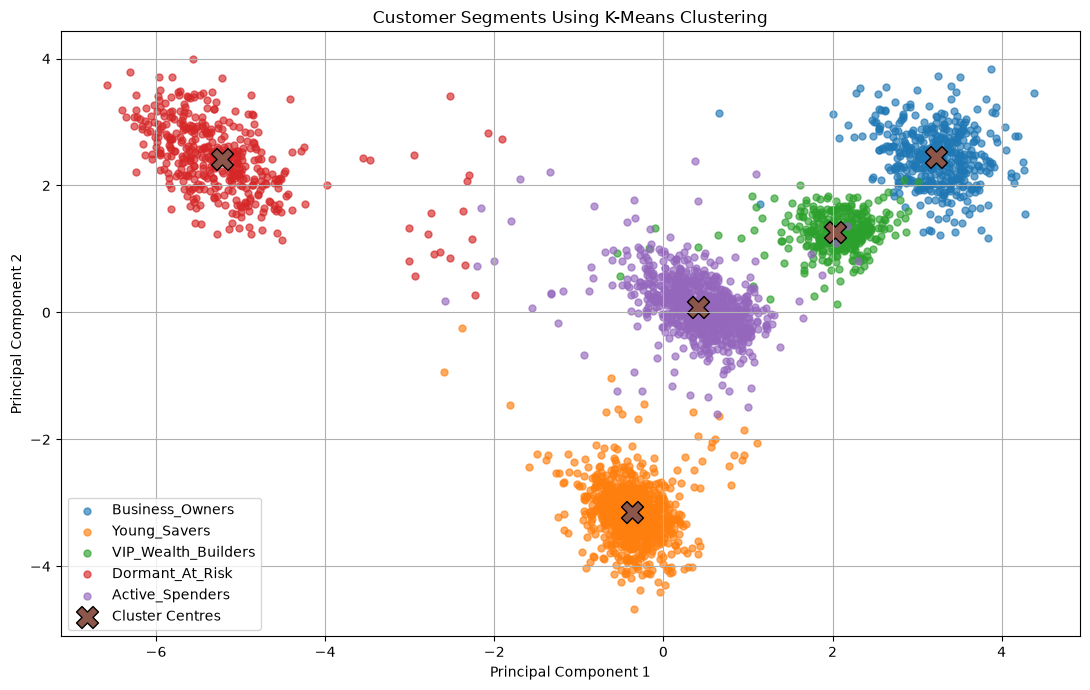

In [33]:
pca_centres = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(11, 7))

for segment in pca_df["segment"].unique():
    segment_data = pca_df[pca_df["segment"] == segment]

    plt.scatter(
        segment_data["PCA_1"],
        segment_data["PCA_2"],
        label=segment,
        alpha=0.65,
        s=25
    )

plt.scatter(
    pca_centres[:, 0],
    pca_centres[:, 1],
    marker="X",
    s=250,
    edgecolors="black",
    label="Cluster Centres"
)

plt.title("Customer Segments Using K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

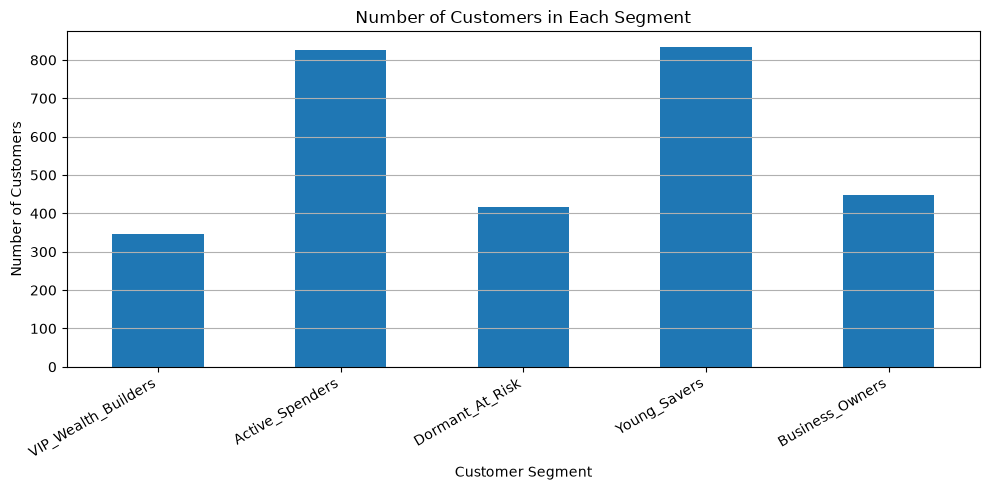

In [34]:
segment_order = [
    "VIP_Wealth_Builders",
    "Active_Spenders",
    "Dormant_At_Risk",
    "Young_Savers",
    "Business_Owners"
]

segment_plot_data = (
    df_clustered["segment"]
    .value_counts()
    .reindex(segment_order)
)

plt.figure(figsize=(10, 5))

segment_plot_data.plot(
    kind="bar"
)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [35]:
profile_check = cluster_profiles_readable.copy()

profile_check.insert(
    0,
    "segment",
    profile_check.index.map(cluster_name_map)
)

profile_check["customer_count"] = (
    df_clustered["cluster_id"]
    .value_counts()
    .sort_index()
)

profile_check["percentage"] = (
    profile_check["customer_count"]
    / len(df_clustered)
    * 100
).round(2)

front_columns = [
    "segment",
    "customer_count",
    "percentage"
]

remaining_columns = [
    column for column in profile_check.columns
    if column not in front_columns
]

profile_check = profile_check[
    front_columns + remaining_columns
]

display(profile_check.round(2))

,segment,customer_count,percentage,avg_monthly_balance,balance_volatility_ratio,balance_growth_rate,txn_frequency_per_month,active_months_ratio,days_since_last_txn,avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,account_tenure_months,num_active_products,overdraft_month_count,digital_channel_ratio
cluster_id,,,,,,,,,,,,,,,,,,
0,Dormant_At_Risk,416,14.50,5564.26,2.31,-0.88,0.90,0.47,227.63,1232.36,0.63,0.00,-0.44,0.77,61.44,1.00,7.56,0.30
1,Young_Savers,833,29.03,141505.15,0.25,0.84,2.31,0.86,8.67,952.66,0.58,0.00,0.48,0.39,12.39,1.25,0.01,0.94
2,VIP_Wealth_Builders,347,12.09,3478115.87,0.11,0.09,4.19,0.92,4.13,71357.37,0.78,0.24,0.14,0.56,88.64,4.20,0.01,0.21
3,Active_Spenders,826,28.79,204036.62,0.38,0.08,8.28,0.95,2.77,3677.89,0.88,0.00,-0.08,0.73,37.19,2.96,0.81,0.87
4,Business_Owners,447,15.58,2280708.63,0.53,0.17,11.78,0.99,1.83,118701.74,1.32,0.37,-0.00,0.61,73.65,6.14,0.71,0.55


In [36]:
centroid_scores = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=feature_columns
)

centroid_scores.index.name = "cluster_id"

for cluster_id in centroid_scores.index:
    print("\n" + "=" * 60)
    print(
        f"CLUSTER {cluster_id} — "
        f"{cluster_name_map.get(cluster_id, 'Not assigned')}"
    )
    print("=" * 60)

    cluster_features = pd.DataFrame({
        "feature": feature_columns,
        "standardized_score": centroid_scores.loc[cluster_id].values
    })

    print("\nFeatures higher than the overall average:")
    display(
        cluster_features
        .sort_values("standardized_score", ascending=False)
        .head(5)
        .round(2)
    )

    print("Features lower than the overall average:")
    display(
        cluster_features
        .sort_values("standardized_score")
        .head(5)
        .round(2)
    )


CLUSTER 0 — Dormant_At_Risk

Features higher than the overall average:


,feature,standardized_score
1,log_balance_volatility_ratio,2.23
5,log_days_since_last_txn,2.13
13,log_overdraft_month_count,1.98
10,debit_txn_share,1.03
11,log_account_tenure_months,0.67


Features lower than the overall average:


,feature,standardized_score
4,active_months_ratio,-2.05
0,log_avg_monthly_balance,-1.82
2,balance_growth_rate,-1.62
3,log_txn_frequency_per_month,-1.54
9,net_cash_flow_ratio,-1.43



CLUSTER 1 — Young_Savers

Features higher than the overall average:


...

,feature,standardized_score
8,high_value_txn_ratio,-0.59
5,log_days_since_last_txn,-0.56
9,net_cash_flow_ratio,-0.43
1,log_balance_volatility_ratio,-0.24
6,log_avg_txn_amount,-0.18



CLUSTER 4 — Business_Owners

Features higher than the overall average:


,feature,standardized_score
8,high_value_txn_ratio,1.93
7,txn_amount_cv,1.74
12,num_active_products,1.73
6,log_avg_txn_amount,1.64
3,log_txn_frequency_per_month,1.29


Features lower than the overall average:


,feature,standardized_score
5,log_days_since_last_txn,-0.75
14,digital_channel_ratio,-0.45
9,net_cash_flow_ratio,-0.20
13,log_overdraft_month_count,-0.04
2,balance_growth_rate,-0.02


In [37]:
# Apply the verified segment mapping
df_clustered["segment"] = (
    df_clustered["cluster_id"]
    .map(cluster_name_map)
)

# Detect the customer identifier column
identifier_columns = [
    column for column in df_clustered.columns
    if column.lower() in [
        "customer_id",
        "customerid",
        "account_id",
        "accountid",
        "id"
    ]
]

# Keep ID, cluster label and segment name at the beginning
front_columns = identifier_columns + [
    "cluster_id",
    "segment"
]

remaining_columns = [
    column for column in df_clustered.columns
    if column not in front_columns
]

final_customer_data = df_clustered[
    front_columns + remaining_columns
]

# Create evaluation table
evaluation_results = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Score"
    ],
    "Value": [
        silhouette,
        davies_bouldin,
        calinski_harabasz
    ]
})

# Save all final outputs
final_customer_data.to_csv(
    "final_customer_clusters.csv",
    index=False
)

profile_check.to_csv(
    "final_cluster_profiles.csv"
)

segment_counts.to_csv(
    "final_segment_distribution.csv"
)

evaluation_results.to_csv(
    "kmeans_evaluation_results.csv",
    index=False
)

print("Final files saved successfully:")
print("1. final_customer_clusters.csv")
print("2. final_cluster_profiles.csv")
print("3. final_segment_distribution.csv")
print("4. kmeans_evaluation_results.csv")

display(final_customer_data.head(10))

Final files saved successfully:
1. final_customer_clusters.csv
2. final_cluster_profiles.csv
3. final_segment_distribution.csv
4. kmeans_evaluation_results.csv


,customer_id,cluster_id,segment,log_avg_monthly_balance,log_balance_volatility_ratio,balance_growth_rate,log_txn_frequency_per_month,active_months_ratio,log_days_since_last_txn,log_avg_txn_amount,txn_amount_cv,high_value_txn_ratio,net_cash_flow_ratio,debit_txn_share,log_account_tenure_months,num_active_products,log_overdraft_month_count,digital_channel_ratio
0,4568,4,Business_Owners,14.108626,0.429545,0.124513,2.377486,1.000000,1.609438,11.853256,1.339462,0.380682,-0.013393,0.602273,4.615121,5.0,0.693147,0.585227
1,4575,4,Business_Owners,14.180201,0.260070,0.594323,2.623057,1.000000,1.098612,11.563021,1.073933,0.347826,-0.117187,0.652174,4.276666,6.0,0.000000,0.495652
2,4576,1,Young_Savers,12.069713,0.300179,0.866448,1.252763,0.833333,2.302585,6.836689,0.433865,0.000000,0.590075,0.266667,1.791759,2.0,0.000000,0.800000
3,4577,1,Young_Savers,11.439775,0.203767,0.818096,1.280934,0.933333,2.833213,6.681168,0.581827,0.000000,0.479429,0.435897,2.772589,1.0,0.000000,0.923077
4,4578,1,Young_Savers,12.159989,0.271701,0.875403,1.232144,0.857143,1.609438,7.058707,0.750023,0.000000,0.598006,0.352941,1.945910,1.0,0.000000,0.941176
5,4579,2,VIP_Wealth_Builders,15.076884,0.112925,-0.009571,1.516348,0.888889,1.945910,11.284791,0.859917,0.234375,-0.000844,0.562500,4.532599,4.0,0.000000,0.250000
6,4581,0,Dormant_At_Risk,11.542485,0.941554,-0.857121,0.693147,0.666667,0.693147,6.963029,0.656598,0.000000,0.103205,0.555556,3.806662,1.0,1.945910,0.166667
7,4582,1,Young_Savers,11.846641,0.187306,0.825141,1.187166,0.888889,3.044522,6.872242,0.664070,0.000000,0.477113,0.439024,2.995732,1.0,0.000000,0.926829
8,4583,4,Business_Owners,14.749778,0.460823,-0.054749,2.594425,1.000000,1.386294,11.741705,1.131691,0.399103,0.047891,0.587444,4.248495,8.0,0.000000,0.524664
9,4584,1,Young_Savers,11.608512,0.207320,0.905847,1.058607,0.823529,2.890372,7.019252,0.750502,0.000000,0.600383,0.375000,2.890372,1.0,0.000000,0.906250
